# Symmetry, phase, and limits: three ideas that carry you through E&M, quantum mechanics, and QIS
### a written guide for when the formulas feel like a pile, with every claim checked in SymPy

If electricity and magnetism and quantum mechanics feel like hundreds of unrelated formulas, here's
a different way in. Most of those formulas are consequences of **three ideas**:

1. **Symmetry.** What can you change without changing anything you could measure? Every answer
   to that question gives you a conservation law or a shortcut.
2. **Phase.** Waves carry a part you can't see directly, but it decides where they add and where
   they cancel. In quantum information, phase *is* the information.
3. **Limits.** Calculus limits are how physicists build idealized objects (point charges, dipoles,
   smooth rotations). They're also the fastest way to check whether an answer is right.

Each section explains the idea in words first, then shows it in E&M, then QM, then QIS. Then a
SymPy cell checks the claim, so you don't have to take it on trust. The last two sections cover
how to use these ideas on homework (Mastering Physics-style problems), and the "machines
discovering physics" figure from the Physics-AI Symbiosis paper.

Every figure uses the Okabe–Ito colorblind-safe palette, distinguishes curves by line style as
well as color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import symmetry_phase_limits as s
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

---
# Part 1: Symmetry

**The idea in one sentence:** if you can change something about your description and *nothing
measurable changes*, nature is telling you something is conserved, or that a formula has to take
a particular shape.

You already use this. To find the field of a charged sphere with Gauss's law, you argue that the
field must point radially and be the same everywhere on a sphere, because rotating the problem
changes nothing. Symmetry did most of the work before any integral.

### 1a. E&M: the potentials are not unique (gauge symmetry)

$\mathbf E$ and $\mathbf B$ are what a charge actually feels. The potentials $V$ and $\mathbf A$
are bookkeeping, and you can shift them by any function $\chi(\mathbf r,t)$:

$$\mathbf A\to\mathbf A+\nabla\chi,\qquad V\to V-\frac{\partial\chi}{\partial t}.$$

$\mathbf E=-\nabla V-\partial_t\mathbf A$ and $\mathbf B=\nabla\times\mathbf A$ don't change,
because the curl of a gradient is zero and the two time derivatives cancel. Check it with completely
arbitrary functions:

In [2]:
dE, dB = s.em_gauge_check()
print("change in E:", list(dE), "   change in B:", list(dB))

change in E: [0, 0, 0]    change in B: [0, 0, 0]


### 1b. E&M: charge can't appear or disappear

Take the divergence of the Ampère–Maxwell law. The divergence of a curl is always zero, and Gauss's
law turns $\nabla\cdot\mathbf E$ into charge density. What's left is the **continuity
equation** $\partial_t\rho+\nabla\cdot\mathbf J=0$: any charge that leaves a region flows out
through its surface. Maxwell added the displacement current partly so that this would hold.

In [3]:
print("d(rho)/dt + div J, built from Maxwell's equations:", s.charge_conservation_from_maxwell())

d(rho)/dt + div J, built from Maxwell's equations: 0


### 1c. Quantum mechanics: the same symmetry, seen from the wavefunction

Multiply a wavefunction by a constant phase, $\psi\to e^{ia}\psi$, and every probability
$|\psi|^2$ stays the same. That's a **global** symmetry:

In [4]:
print("|e^{ia} psi|^2 - |psi|^2 =", s.global_phase_check())

|e^{ia} psi|^2 - |psi|^2 = 0


Now let the phase vary from place to place: $\psi\to e^{iq\chi(x,t)/\hbar}\psi$. On its own,
this breaks the Schrödinger equation, because the derivatives hit $\chi$ and leave extra terms:

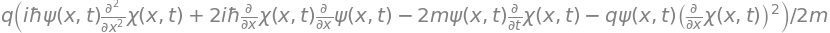

In [5]:
s.global_only_breaks_without_A()

Here's the remarkable part. If the particle couples to the electromagnetic potentials through
$\hat p\to\hat p-q\mathbf A$ ("minimal coupling"), and you shift $\mathbf A$ and $V$ by **the
same $\chi$** as in 1a, every extra term cancels:

In [6]:
print("Schrodinger residual after (local phase + gauge shift of A, V):", s.local_gauge_schrodinger_check())

Schrodinger residual after (local phase + gauge shift of A, V):

 0


**Read that slowly.** Asking the quantum phase to be freely choosable at every point *forces*
the existence of a field that transforms exactly like the electromagnetic potential. Modern physics
takes this as the reason electromagnetism exists. The same argument with bigger symmetry groups
gives the weak and strong forces.

### 1d. Noether's theorem: symmetry means conservation

In quantum mechanics a quantity $O$ is conserved when it commutes with the Hamiltonian, since
$\frac{d}{dt}\langle O\rangle=\frac{i}{\hbar}\langle[H,O]\rangle$. Test momentum:

In [7]:
free, pot = s.noether_commutators()
print("[H, p] f, free particle:       ", free)
print("[H, p] f, with potential V(x): ", pot)

[H, p] f, free particle:        0
[H, p] f, with potential V(x):  I*hbar*f(x)*Derivative(V(x), x)


A free particle looks the same if you shift it, so momentum is conserved. A potential $V(x)$
breaks that shift symmetry, and the commutator is exactly $i\hbar V'$. Plugging it in gives
$\frac{d}{dt}\langle p\rangle=\frac{i}{\hbar}\langle i\hbar V'\rangle=-\langle V'\rangle$, the
average force. Newton's second law falls out of a commutator (Ehrenfest's theorem; see
`dgs.ehrenfest_theorem`).

### 1e. Quantum information: symmetries are gates

Every quantum gate is a **unitary** transformation, one that preserves the total probability.
Unitaries are symmetries of the inner product $\langle\psi|\phi\rangle$. Building a quantum
computer means applying a carefully chosen sequence of these symmetries.

---
# Part 2: Phase

**The idea in one sentence:** a wave has a size (amplitude) and a position in its cycle (phase).
Detectors measure size, but phase decides what happens when waves combine.

### 2a. E&M: phase velocity vs group velocity

A wave $e^{i(kx-\omega t)}$ has crests that move at the **phase velocity** $\omega/k$. A pulse,
the envelope that carries energy and information, moves at the **group velocity**
$d\omega/dk$. With index of refraction $n(k)$:

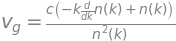

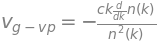

In [8]:
vp, vg, diff = s.phase_group_velocity_symbolic()
display(sp.Eq(sp.Symbol("v_p"), vp), sp.Eq(sp.Symbol("v_g"), vg), sp.Eq(sp.Symbol("v_g - v_p"), diff))

The two speeds differ only if $n$ depends on $k$, which is called **dispersion**. This whole
repo is built on that difference. Dispersion turns spectral phase into a time-domain shape (Jalali's
time-stretch), and phase retrieval works it backwards. In AC circuits the same mathematics appears
as **phasors**: a voltage's phase relative to the current tells you whether a component stores or
dissipates energy.

### 2b. Quantum mechanics: relative phase makes interference

Send a particle down two paths that differ in phase by $\phi$. The detection probability is
$|1+e^{i\phi}|^2/4=\cos^2(\phi/2)$, even though each path alone gives the same probability:

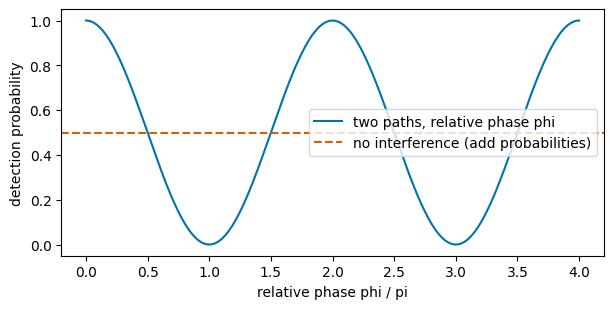

Figure description: detection probability oscillates between 1 and 0 as the relative phase changes (solid), while adding probabilities instead of amplitudes would give a flat 1/2 (dashed).


In [9]:
ph = np.linspace(0, 4*np.pi, 400)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ph/np.pi, s.relative_phase_interference(ph), "-", label="two paths, relative phase phi")
ax.axhline(0.5, ls="--", c=OI[1], label="no interference (add probabilities)")
ax.set_xlabel("relative phase phi / pi"); ax.set_ylabel("detection probability"); ax.legend(); plt.show()
print("Figure description: detection probability oscillates between 1 and 0 as the relative phase changes (solid), "
      "while adding probabilities instead of amplitudes would give a flat 1/2 (dashed).")

This is the double-slit experiment, the Mach–Zehnder interferometer, and every quantum sensor
in this repo (atom gyroscopes, NV magnetometers, atomic clocks). Each one turns an unknown physical
quantity into a **relative phase**, then into a fringe you can count.

### 2c. Quantum information: global phase is nothing, relative phase is everything

Take the qubit $(|0\rangle+e^{i\phi}|1\rangle)/\sqrt2$ and multiply it by a global phase
$e^{i\gamma}$. Its Bloch vector, which captures everything measurable, is:

In [10]:
s.qubit_global_vs_relative_symbolic().T

[cos(φ)  sin(φ)  0]

$\gamma$ has vanished, as in 1c, but $\phi$ remains: it sets where the qubit points around
the equator. **Decoherence** is the environment scrambling $\phi$, which is why so much of quantum
engineering is about protecting phase (see `dephasing_phase_retrieval` and `quantum_error_correction`).

---
# Part 3: Limits

**The idea in one sentence:** many objects in physics, such as point charges, dipoles, smooth
rotations and continuous spectra, are *limits* of something simpler. The same limits are your best
tool for checking answers.

### 3a. E&M: building a dipole

Put $+q$ and $-q$ a distance $d$ apart. Shrink $d\to0$ while growing $q$ so that $p=qd$ stays
fixed. The exact potential becomes:

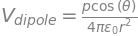

In [11]:
sp.Eq(sp.Symbol("V_dipole"), s.dipole_limit_symbolic())

A $1/r^2$ falloff with a $\cos\theta$ pattern. No dipole is truly point-like, but molecules,
antennas and magnets look like this from far away. That's what the limit means physically.

### 3b. E&M: the point charge as a limit (the delta function)

Spread a unit charge into a Gaussian of width $s$ and squeeze it. The total stays 1 while the peak
grows without bound. Integrated against any smooth function, it picks out the value at the
origin:

In [12]:
area, sift, sift_lim, peak = s.gaussian_delta_limit_symbolic()
print("area =", area, "   integral of g(x) cos(x) =", sift, " -> as s -> 0:", sift_lim, "  (cos 0 = 1)   peak height -> ", peak)

area = 1    integral of g(x) cos(x) = exp(-s**2/2)  -> as s -> 0: 1   (cos 0 = 1)   peak height ->  oo


That's the Dirac delta function $\delta(x)$, the mathematical point charge. It's why
$\nabla\cdot(\hat r/r^2)=4\pi\delta^3(\mathbf r)$ is the content of Gauss's law for a point
charge.

### 3c. Quantum mechanics: the classical world as a limit

The energies of a particle in a box grow as $n^2$. The relative gap between neighboring levels:

In [13]:
ratio, lim = s.correspondence_limit_symbolic()
print("(E_{n+1} - E_n)/E_n =", ratio, "   -> as n -> infinity:", lim)

(E_{n+1} - E_n)/E_n = (2*n + 1)/n**2    -> as n -> infinity: 0


At large quantum numbers the ladder of levels looks continuous, so the motion looks classical.
That's Bohr's **correspondence principle**: quantum mechanics has to reproduce classical physics
in the appropriate limit.

### 3d. Quantum information: building a gate from tiny rotations

A smooth rotation by angle $\theta$ is the limit of many tiny ones:
$\lim_{n\to\infty}(1-i\theta/n)^n=e^{-i\theta}$. This is the same limit that defines $e$ in
calculus. For matrices it builds every quantum gate:

                        ⎡ -ⅈ⋅θ      ⎤
                        ⎢ℯ       0  ⎥
exp(-i theta sigma_z) = ⎢           ⎥
                        ⎢        ⅈ⋅θ⎥
                        ⎣  0    ℯ   ⎦

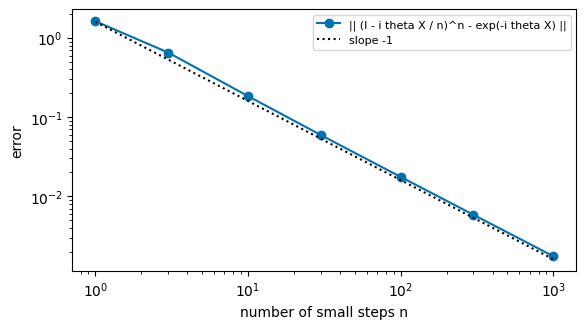

Figure description: the error of approximating a 90-degree X rotation by n small steps falls along a straight line of slope -1 on log-log axes: ten times more steps gives ten times less error.


In [14]:
lim, U = s.infinitesimal_rotation_limit()
display(sp.Eq(sp.Symbol("lim (1 - i theta/n)^n"), lim), sp.Eq(sp.Symbol("exp(-i theta sigma_z)"), U, evaluate=False))
ns_ = np.array([1, 3, 10, 30, 100, 300, 1000])
errs = [s.rotation_power_numeric(np.pi/2, int(n))[1] for n in ns_]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.loglog(ns_, errs, "o-", label="|| (I - i theta X / n)^n - exp(-i theta X) ||")
ax.loglog(ns_, 1.6/ns_, "k:", label="slope -1")
ax.set_xlabel("number of small steps n"); ax.set_ylabel("error"); ax.legend(fontsize=8); plt.show()
print("Figure description: the error of approximating a 90-degree X rotation by n small steps falls along a straight "
      "line of slope -1 on log-log axes: ten times more steps gives ten times less error.")

Hamiltonians are "infinitesimal generators", and gates are the finite rotations they build.
The $1/n$ error is also the basic idea behind **Trotterization**, the way quantum computers
simulate molecules by chopping time evolution into small steps.

---
# Part 4: Using these ideas on homework (Mastering Physics-style problems)

Online homework systems grade only the final expression, so a sign error costs you everything. Run
three quick checks before submitting:

1. **Symmetry check.** Does your answer respect the problem's symmetry? A field on the axis of a
   ring can't have a sideways component. If swapping two identical charges changes your answer,
   something's wrong.
2. **Phase check (waves, circuits, QM).** Did you add *amplitudes* (with their phases) where you
   should have, and probabilities or intensities only at the end?
3. **Limit check.** Take a limit where you already know the answer: $d\to0$, $r\to\infty$,
   $\theta\to0$, $m\to\infty$, $t\to0$. Here's a SymPy tool for it. Example: the
   large-amplitude pendulum period factor must go to 1 as the amplitude goes to 0, and the field of
   a finite line charge seen from very far away must look like a point charge.

In [15]:
th0 = sp.symbols("theta_0", positive=True)
print(s.check_limits(1 + th0**2/16, th0, [(0, 1)]))
lam, L, r_, eps0 = sp.symbols("lambda L r epsilon_0", positive=True)
E_line = lam * L / (4*sp.pi*eps0 * r_ * sp.sqrt(r_**2 + (L/2)**2))      # on the perpendicular bisector
print("finite line, r >> L:", s.check_limits(E_line * r_**2, r_, [(sp.oo, lam*L/(4*sp.pi*eps0))]),
      " -> (lambda L) / (4 pi eps0 r^2): a point charge Q = lambda L")

[(0, 1, True)]
finite line, r >> L: [(oo, L*lambda/(4*pi*epsilon_0), True)]  -> (lambda L) / (4 pi eps0 r^2): a point charge Q = lambda L


If a limit check fails, the answer is wrong, even if you can't yet see where. If it passes,
you've caught most sign and factor-of-2 errors. Professional physicists do this constantly; it's
part of mathematical maturity.

---
# Part 5: How machines "discover" laws, a small version of the paper's Figure 4

The figure you shared compares how humans discover laws with how machines might. A human
compresses many observations into a few numbers and a rule: for a thrown object, $x_0$ and $v$
with $x(t')=x_0+vt'-\tfrac12gt'^2$. The machine (an encoder–decoder network) compresses
observations into a small **latent representation**, then answers questions from it.

You can see that compression without a neural network. Stack 200 throws, each observed at 30 times,
into a 200×30 matrix. Its singular values say how many numbers really describe the data:

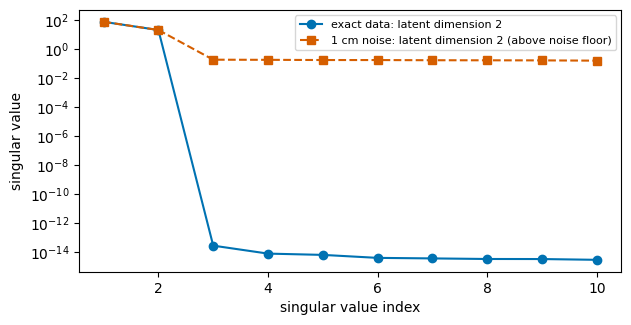

answering 'where is it at t' = 1.5 s?' from just (x0, v): max error 3.6e-15 m
Figure description: singular values of the projectile data. Two are large and the rest drop to rounding error (circles, solid) or to a flat noise floor (squares, dashed): the data really contains two numbers per throw.


In [16]:
X, x0, v, tt = s.projectile_observations(n_throws=200, n_times=30)
k, sv = s.latent_dimension(X)
Xn, *_ = s.projectile_observations(noise=0.01)
kn, svn = s.latent_dimension(Xn, 1e-2)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(range(1, 11), sv[:10], "o-", label=f"exact data: latent dimension {k}")
ax.semilogy(range(1, 11), svn[:10], "s--", label=f"1 cm noise: latent dimension {kn} (above noise floor)")
ax.set_xlabel("singular value index"); ax.set_ylabel("singular value"); ax.legend(fontsize=8); plt.show()
pred, a, b = s.predict_from_two_numbers(X, tt, 1.5)
print(f"answering 'where is it at t' = 1.5 s?' from just (x0, v): max error {np.max(np.abs(pred - (x0 + v*1.5 - 0.5*9.81*1.5**2))):.1e} m")
print("Figure description: singular values of the projectile data. Two are large and the rest drop to rounding error "
      "(circles, solid) or to a flat noise floor (squares, dashed): the data really contains two numbers per throw.")

Two large singular values and nothing else: **30 observations per throw are really 2
numbers**. A neural autoencoder finds the same thing when the relationship is nonlinear and no SVD
can expose it. As the paper notes, current methods still need some physical structure supplied.
Here the structure was the form of the law, used to answer the "question" $x(t')$.

**The common thread with Parts 1–3:** finding the right few numbers *is* finding the symmetry
(what doesn't matter), the phase (what does), and the limits (where the description simplifies).
That's what physics has always done, and it's also what a good latent representation does.

---
## One-page summary

| idea | E&M | quantum mechanics | quantum information |
|---|---|---|---|
| **symmetry** | gauge freedom; charge conservation | global phase; local phase ⇒ electromagnetism; $[H,p]=0$ ⇒ momentum conserved | gates are unitary symmetries |
| **phase** | $v_p$ vs $v_g$, dispersion, phasors | relative phase ⇒ interference | relative phase = information; decoherence destroys it |
| **limits** | dipole ($qd$ fixed), delta function | correspondence $n\to\infty$ | $(1-i\theta\sigma/n)^n\to e^{-i\theta\sigma}$ (Trotter) |
| **on homework** | symmetry first | amplitudes before probabilities | check a known limit |

*Education; every boxed claim above is verified by a SymPy cell or a test in `tests/test_symmetry_phase_limits.py`.*